# Count visits, not darts

Source notebook for the blog post of the same name. It re-solves the
one-dart-at-a-time model of the previous post (*How to play one player 501*),
solves the real three-dart game under both objectives, and scores **every policy
in the real game** with an exact evaluator, so that the comparisons are between
policies and never between models' opinions of themselves.

Figures are written to `POST_FIGURES` (default: the blog repository's
`assets/images/2026-11-count-visits/`, assumed to be checked out next to this
one). Runs in about six minutes on four cores.

In [1]:
import os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle

sys.path.insert(0, str(Path.cwd().parents[1]))  # the repository root
from darts.mdp_3turn import ThreeDartMDP
from darts.transitions import transition_arrays
from darts.dartboards import DARTBOARD_CONSTANTS as C
from darts.utils import aim_description
from darts import players

OUT = Path(os.environ.get(
    "POST_FIGURES",
    Path.cwd().parents[2] / "mjc239.github.io/assets/images/2026-11-count-visits"))
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
BOARD_PIXELS, STRIDE, START = 512, 2, 501

## The machinery

Three solvers and one evaluator.

In [2]:
def build(sigma):
    tr = transition_arrays(BOARD_PIXELS, sigma, point_stride=STRIDE)
    S = tr["allowed_scores"].astype(int)
    order = np.argsort(S)
    tr["S"] = S[order]
    tr["P"] = np.ascontiguousarray(tr["probs"][:, order])
    tr["CP"] = np.ascontiguousarray(tr["checkout_probs"][:, order])
    tr["mm"] = (tr["points"] - BOARD_PIXELS // 2) * tr["mm_per_pixel"]  # (y, x) in mm
    del tr["probs"], tr["checkout_probs"], tr["board"], tr["checkouts"]
    return tr


def solve_memoryless(tr):
    """The previous post's model: every dart is a turn of its own, a bust returns
    to the score that dart was thrown from, and each dart costs one."""
    P, CP, S = tr["P"], tr["CP"], tr["S"]
    V = np.zeros(START + 1)
    pol = np.zeros(START + 1, dtype=int)
    for s in range(2, START + 1):
        valid = (S >= 1) & (S <= s - 2)          # a miss scores 0 and stays on s
        base = 1.0 + P[:, valid] @ V[s - S[valid]]
        stay = 1.0 - P[:, valid].sum(axis=1)
        j = np.searchsorted(S, s)
        if j < len(S) and S[j] == s:
            stay = stay - CP[:, j]               # ...except a checkout
        with np.errstate(divide="ignore"):
            ratio = np.where(stay < 1 - 1e-15, base / (1 - stay), np.inf)
        pol[s] = int(np.argmin(ratio))
        V[s] = ratio[pol[s]]
    return V, pol


def solve_3dart(tr, objective):
    costs = {"darts": dict(dart_cost=1.0, turn_cost=0.0),
             "visits": dict(dart_cost=0.0, turn_cost=1.0)}[objective]
    return ThreeDartMDP(tr["P"], tr["CP"], tr["S"], START, **costs).solve()


def as_policy(m):
    if isinstance(m, np.ndarray):                 # memoryless: the score is all it sees
        return lambda u, d, s: int(m[u])
    return lambda u, d, s: m.policy(u, d, s)


def outcome(tr, i, u):
    """(checkout, bust, legal-remainder-scores, their probabilities) for one dart."""
    P, CP, S = tr["P"], tr["CP"], tr["S"]
    j = np.searchsorted(S, u)
    co = CP[i, j] if (j < len(S) and S[j] == u) else 0.0
    valid = S <= u - 2
    return co, 1.0 - P[i, valid].sum() - co, S[valid], P[i, valid]


def visit_matrix(tr, policy):
    """
    Exact visit-to-visit chain of a fixed policy under the real rules.
    T[s, s'] = P(a visit started on s ends with s' left); s' = 0 is a checkout,
    and s' = s includes every bust. Also returns the expected darts thrown in a
    visit from s.
    """
    T = np.zeros((START + 1, START + 1))
    thrown = np.zeros(START + 1)
    for s in range(2, START + 1):
        dist = {s: 1.0}
        for dart in (1, 2, 3):
            nxt = {}
            for u, w in dist.items():
                co, bust, ts, ps = outcome(tr, policy(u, dart, s), u)
                thrown[s] += w
                T[s, 0] += w * co
                T[s, s] += w * bust
                for t, p in zip(ts, ps):
                    if p > 0:
                        nxt[u - t] = nxt.get(u - t, 0.0) + w * p
            dist = nxt
        for u, w in dist.items():
            T[s, u] += w
    return T, thrown


def evaluate(T, thrown):
    """Expected visits and darts to finish, from every score, for a visit chain."""
    visits, darts = np.zeros(START + 1), np.zeros(START + 1)
    for s in range(2, START + 1):
        row = T[s, 1:s]
        stay = T[s, s]
        visits[s] = (1.0 + row @ visits[1:s]) / (1.0 - stay)
        darts[s] = (thrown[s] + row @ darts[1:s]) / (1.0 - stay)
    return visits, darts


def finished_by(T, start=START, k_max=400):
    """P(checked out within k visits), for k = 0..k_max."""
    T = T.copy(); T[0, :] = 0.0; T[0, 0] = 1.0
    x = np.zeros(START + 1); x[start] = 1.0
    out = np.zeros(k_max + 1)
    for k in range(1, k_max + 1):
        x = x @ T
        out[k] = x[0]
    return out


def race(fa, fb, a_first):
    """P(A checks out before B), alternating visits, each playing their own policy."""
    k = np.arange(1, len(fa))
    b_done = fb[k - 1] if a_first else fb[np.minimum(k, len(fb) - 1)]
    return float((np.diff(fa) * (1.0 - b_done)).sum())

In [3]:
def q_visits(tr, mv, u, d, s, i):
    """Expected visits to finish after aiming at point i from (u, d, s), then optimal."""
    co, bust, ts, ps = outcome(tr, i, u)
    nxt = np.array([-mv.V1[u - t] if d == 3 else -mv.value(u - t, d + 1, s) for t in ts])
    return (1.0 if d == 1 else 0.0) + ps @ nxt + bust * -mv.V1[s]


def decompose(tr, policy, mv):
    """
    Where a policy loses its visits. By the performance-difference identity,
    J(policy) - J* = sum over states of [how often policy reaches the state] x
    [what its choice there costs, valued under optimal play afterwards]. Exact,
    and it must add up to the difference the evaluator reports.
    """
    inflow = np.zeros(START + 1); inflow[START] = 1.0
    rows = []
    for s in range(START, 1, -1):
        if inflow[s] < 1e-14:
            continue
        dist, layers, stay = {s: 1.0}, [], 0.0
        for dart in (1, 2, 3):
            layers.append(dist)
            nxt = {}
            for u, w in dist.items():
                co, bust, ts, ps = outcome(tr, policy(u, dart, s), u)
                stay += w * bust
                for t, p in zip(ts, ps):
                    if p > 0:
                        nxt[u - t] = nxt.get(u - t, 0.0) + w * p
            dist = nxt
        stay += dist.pop(s, 0.0)
        Y = inflow[s] / (1.0 - stay)            # expected visits started on s
        for u, w in dist.items():
            inflow[u] += Y * w
        for dart, layer in zip((1, 2, 3), layers):
            for u, w in layer.items():
                if Y * w < 1e-10:
                    continue
                i = policy(u, dart, s)
                loss = q_visits(tr, mv, u, dart, s, i) + mv.value(u, dart, s)
                rows.append((u, dart, s, Y * w, loss))
    return pd.DataFrame(rows, columns=["score", "dart", "visit_start", "occupancy", "loss"])

## Solve every band

The seven shared ability bands, plus the 40 mm player the previous post used.

In [4]:
BANDS = dict(players.ABILITY_BANDS)
BANDS["previous post"] = 40.0
KEEP = {"county", "pub", "previous post"}   # bands whose full models the figures need

rows, kept = [], {}
for band, sigma in BANDS.items():
    t0 = time.perf_counter()
    tr = build(sigma)
    Vmem, pmem = solve_memoryless(tr)
    md_, mv_ = solve_3dart(tr, "darts"), solve_3dart(tr, "visits")
    res = {}
    for name, pol in [("visits", as_policy(mv_)), ("darts", as_policy(md_)),
                      ("memoryless", as_policy(pmem))]:
        T, thrown = visit_matrix(tr, pol)
        v, d = evaluate(T, thrown)
        res[name] = dict(T=T, visits=v, darts=d, done=finished_by(T))
    # the evaluator must agree with each solver about its own policy
    assert abs(res["visits"]["visits"][START] + mv_.V1[START]) < 1e-8
    assert abs(res["darts"]["darts"][START] + md_.V1[START]) < 1e-8
    opt = res["visits"]["done"]
    row = dict(band=band, sigma_mm=sigma,
               avg=3 * 501 / -md_.V1[START],
               first=race(opt, opt, True) - 0.5,
               memoryless_forecast_darts=Vmem[START])
    for name, r in res.items():
        row[f"{name}_visits"] = r["visits"][START]
        row[f"{name}_darts"] = r["darts"][START]
        row[f"{name}_win"] = 0.5 * (race(r["done"], opt, True) + race(r["done"], opt, False))
    rows.append(row)
    if band in KEEP:
        kept[band] = dict(tr=tr, mv=mv_, md=md_, pmem=pmem, Vmem=Vmem, res=res)
    print(f"{band:>14}  {sigma:5.1f} mm  {time.perf_counter() - t0:5.1f} s", flush=True)

table = pd.DataFrame(rows).set_index("band")

         elite    6.5 mm   35.2 s


           pro    8.0 mm   33.1 s


        county   10.0 mm   33.3 s


  super_league   13.0 mm   36.6 s


        league   16.0 mm   36.6 s


          club   20.0 mm   39.5 s


           pub   28.0 mm   43.5 s


 previous post   40.0 mm   46.7 s


In [5]:
show = pd.DataFrame({
    "sigma (mm)": table.sigma_mm,
    "3-dart avg": table.avg.round(1),
    "visits: optimal": table.visits_visits.round(3),
    "visits: count darts": table.darts_visits.round(3),
    "visits: one dart a turn": table.memoryless_visits.round(3),
    "lost: count darts": (table.darts_visits - table.visits_visits).round(3),
    "lost: one dart a turn": (table.memoryless_visits - table.visits_visits).round(3),
    "darts: optimal-for-visits": table.visits_darts.round(2),
    "darts: count darts": table.darts_darts.round(2),
    "win pts lost: count darts": (100 * (0.5 - table.darts_win)).round(2),
    "win pts lost: one dart a turn": (100 * (0.5 - table.memoryless_win)).round(2),
    "throwing first (pts)": (100 * table.first).round(1),
    "one-dart model's own forecast (darts)": table.memoryless_forecast_darts.round(2),
    "one-dart policy, real darts": table.memoryless_darts.round(2),
})
show.T

band,elite,pro,county,super_league,league,club,pub,previous post
sigma (mm),6.500,8.000,10.000,13.000,16.000,20.000,28.000,40.000
3-dart avg,100.100,88.800,76.500,62.200,51.900,42.800,32.300,23.700
visits: optimal,5.321,5.974,6.904,8.470,10.187,12.472,17.023,24.616
visits: count darts,5.351,6.005,6.948,8.557,10.312,12.687,17.521,25.704
visits: one dart a turn,5.374,6.022,6.967,8.550,10.332,12.785,17.759,26.405
lost: count darts,0.030,0.031,0.043,0.087,0.124,0.215,0.499,1.088
lost: one dart a turn,0.053,0.048,0.063,0.080,0.145,0.313,0.736,1.789
darts: optimal-for-visits,15.050,16.940,19.690,24.240,29.110,35.400,47.110,64.750
darts: count darts,15.010,16.920,19.650,24.170,28.980,35.130,46.490,63.500
win pts lost: count darts,0.580,0.360,0.320,0.460,0.560,0.660,1.160,1.600


## Expected visits from every score

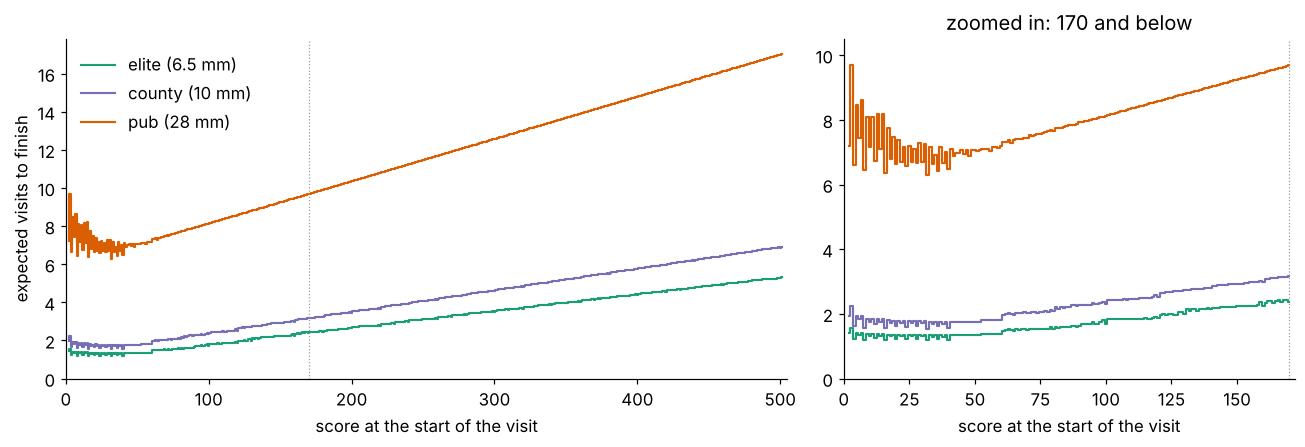

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
colours = {"elite": "#1b9e77", "county": "#7570b3", "pub": "#d95f02"}
full = {}
for band in colours:
    # cheap to re-solve one objective for the three bands plotted
    if band in kept:
        full[band] = -kept[band]["mv"].V1
    else:
        full[band] = -solve_3dart(build(BANDS[band]), "visits").V1
for band, c in colours.items():
    v = full[band]
    s = np.arange(2, START + 1)
    axes[0].step(s, v[2:], where="mid", color=c, lw=1.4,
                 label=f"{band} ({BANDS[band]:g} mm)")
    s = np.arange(2, 171)
    axes[1].step(s, v[2:171], where="mid", color=c, lw=1.4)
axes[0].set(xlabel="score at the start of the visit", ylabel="expected visits to finish",
            xlim=(0, 505), ylim=(0, None))
axes[1].set(xlabel="score at the start of the visit", xlim=(0, 172), ylim=(0, 10.5),
            title="zoomed in: 170 and below")
for ax in axes:
    ax.axvline(170, color="0.6", lw=0.8, ls=":")
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "visits-by-score.png", bbox_inches="tight")

In [7]:
v = full["county"]
print("county: 501 ->", round(v[501], 3), "| 170 ->", round(v[170], 3),
      "| 171 ->", round(v[171], 3), "| 100 ->", round(v[100], 3), "| 40 ->", round(v[40], 3))
for band in colours:
    v = full[band]
    print(band, {s: round(v[s], 2) for s in (40, 99, 100, 101, 159, 160, 161, 169, 170, 171)})

county: 501 -> 6.904 | 170 -> 3.159 | 171 -> 3.168 | 100 -> 2.312 | 40 -> 1.569
elite {40: np.float64(1.2), 99: np.float64(1.82), 100: np.float64(1.7), 101: np.float64(1.84), 159: np.float64(2.36), 160: np.float64(2.25), 161: np.float64(2.32), 169: np.float64(2.43), 170: np.float64(2.37), 171: np.float64(2.44)}
county {40: np.float64(1.57), 99: np.float64(2.38), 100: np.float64(2.31), 101: np.float64(2.41), 159: np.float64(3.02), 160: np.float64(2.99), 161: np.float64(3.08), 169: np.float64(3.15), 170: np.float64(3.16), 171: np.float64(3.17)}
pub {40: np.float64(6.48), 99: np.float64(8.1), 100: np.float64(8.12), 101: np.float64(8.16), 159: np.float64(9.44), 160: np.float64(9.46), 161: np.float64(9.48), 169: np.float64(9.66), 170: np.float64(9.68), 171: np.float64(9.7)}


## The madhouse

The values of the even finishes from 2 to 40, under each objective.

county visits: V(2) - V(4) = 0.316 | darts: V(2) - V(4) = -0.003
pub visits: V(2) - V(4) = 0.584 | darts: V(2) - V(4) = -0.058
previous post visits: V(2) - V(4) = 0.645 | darts: V(2) - V(4) = -0.106


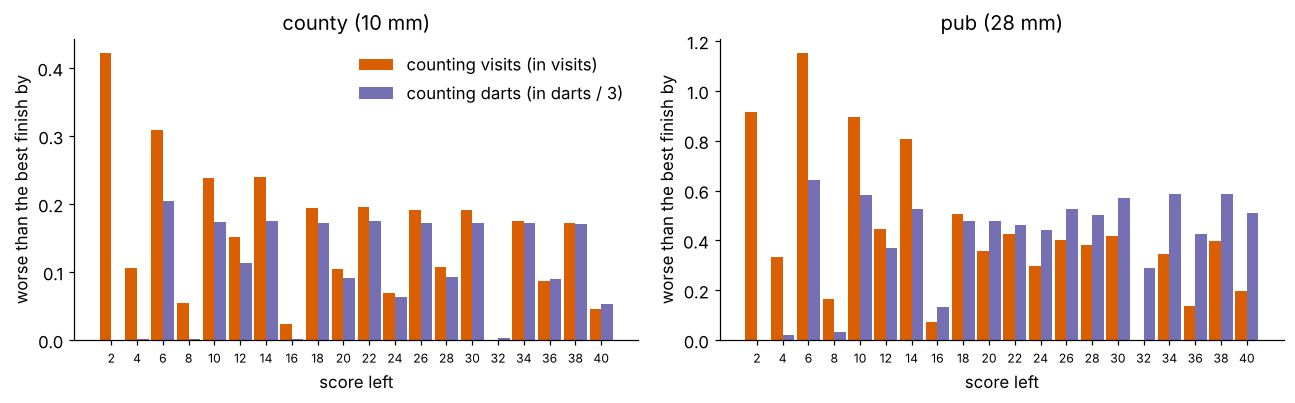

In [8]:
evens = np.arange(2, 41, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, band in zip(axes, ["county", "pub"]):
    k = kept[band]
    vis = -k["mv"].V1[evens]
    drt = -k["md"].V1[evens]
    ax.bar(evens - 0.45, vis - vis.min(), width=0.9, color="#d95f02",
           label="counting visits (in visits)")
    ax.bar(evens + 0.45, (drt - drt.min()) / 3, width=0.9, color="#7570b3",
           label="counting darts (in darts / 3)")
    ax.set(title=f"{band} ({BANDS[band]:g} mm)", xlabel="score left",
           ylabel="worse than the best finish by", xticks=evens)
    ax.tick_params(axis="x", labelsize=8)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "madhouse.png", bbox_inches="tight")

for band in ["county", "pub", "previous post"]:
    k = kept[band]
    print(band, "visits: V(2) - V(4) =", round(-k["mv"].V1[2] + k["mv"].V1[4], 3),
          "| darts: V(2) - V(4) =", round(-k["md"].V1[2] + k["md"].V1[4], 3))

## Where to aim on 2, dart by dart

In [9]:
def draw_board(ax, r_max=C["DOUBLE_OUTER_RADIUS"] + 20, labels=True):
    """A conventional board in mm, 20 at the top."""
    order = [20, 1, 18, 4, 13, 6, 10, 15, 2, 17, 3, 19, 7, 16, 8, 11, 14, 9, 12, 5]
    rings = [(C["DOUBLE_INNER_RADIUS"], C["DOUBLE_OUTER_RADIUS"], True),
             (C["TRIPLE_OUTER_RADIUS"], C["DOUBLE_INNER_RADIUS"], False),
             (C["TRIPLE_INNER_RADIUS"], C["TRIPLE_OUTER_RADIUS"], True),
             (C["OUTER_BULLSEYE_RADIUS_MM"], C["TRIPLE_INNER_RADIUS"], False)]
    ax.add_patch(Circle((0, 0), r_max, color="#222222", zorder=0))
    for k, n in enumerate(order):
        centre = 90 - 18 * k
        lo, hi = centre - 9, centre + 9
        for r0, r1, scoring in rings:
            if scoring:
                col = "#c8102e" if k % 2 == 0 else "#007a33"
            else:
                col = "#1a1a1a" if k % 2 == 0 else "#efe6cf"
            ax.add_patch(Wedge((0, 0), r1, lo, hi, width=r1 - r0, facecolor=col,
                               edgecolor="#9a9a9a", lw=0.4, zorder=1))
        if labels:
            a = np.deg2rad(centre)
            ax.text(181 * np.cos(a), 181 * np.sin(a), str(n), color="white",
                    ha="center", va="center", fontsize=9, zorder=3)
    ax.add_patch(Circle((0, 0), C["OUTER_BULLSEYE_RADIUS_MM"], facecolor="#007a33",
                        edgecolor="#9a9a9a", lw=0.4, zorder=1))
    ax.add_patch(Circle((0, 0), C["INNER_BULLSEYE_RADIUS_MM"], facecolor="#c8102e",
                        edgecolor="#9a9a9a", lw=0.4, zorder=1))
    ax.set_aspect("equal"); ax.axis("off")


def xy(tr, i):
    y, x = tr["mm"][i]
    return x, y


def describe(tr, i, u):
    co, bust, ts, ps = outcome(tr, i, u)
    miss = ps[ts == 0].sum()
    return co, bust, miss

county mv dart 1 outside D1 checkout 0.261  bust 0.163  miss 0.576
county mv dart 2 outside D1 checkout 0.277  bust 0.193  miss 0.531
county mv dart 3 D1 checkout 0.307  bust 0.357  miss 0.336
county md dart 1 D1 checkout 0.307  bust 0.357  miss 0.336
county md dart 2 D1 checkout 0.307  bust 0.357  miss 0.336
county md dart 3 D1 checkout 0.307  bust 0.357  miss 0.336
pub mv dart 1 outside D1 checkout 0.069  bust 0.314  miss 0.617
pub mv dart 2 outside D1 checkout 0.069  bust 0.314  miss 0.617
pub mv dart 3 D1 checkout 0.074  bust 0.465  miss 0.461
pub md dart 1 D1 checkout 0.074  bust 0.465  miss 0.461
pub md dart 2 D1 checkout 0.074  bust 0.465  miss 0.461
pub md dart 3 D1 checkout 0.074  bust 0.465  miss 0.461


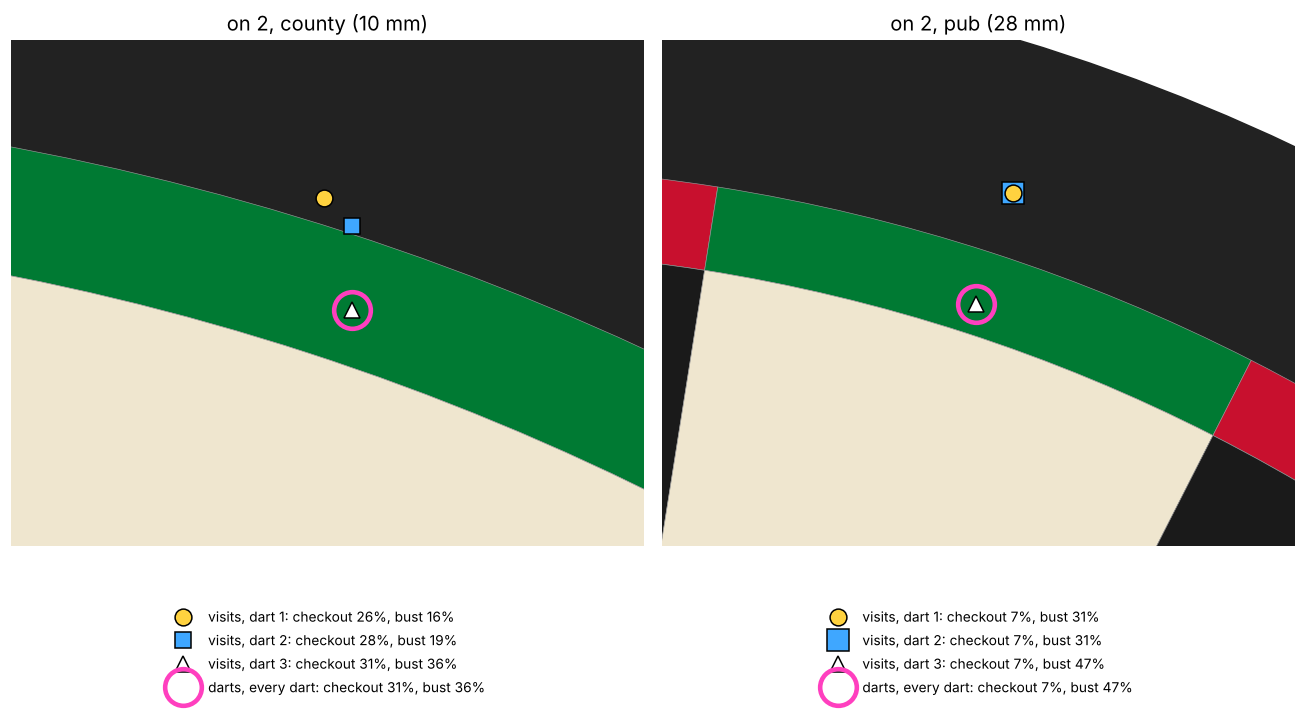

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, band in zip(axes, ["county", "pub"]):
    k = kept[band]; tr = k["tr"]
    draw_board(ax, labels=False)
    # zoom in on the double 1, which sits 18 degrees clockwise of the top
    a = np.deg2rad(72); cx, cy = 166 * np.cos(a), 166 * np.sin(a)
    w = 20 if band == "county" else 30
    ax.set_xlim(cx - w, cx + w); ax.set_ylim(cy - 0.8 * w, cy + 0.8 * w)
    style = {1: ("o", "#ffd23f"), 2: ("s", "#3fa7ff"), 3: ("^", "#ffffff")}
    lines = []
    for d in (1, 2, 3):
        i = k["mv"].policy(2, d, 2)
        co, bust, miss = describe(tr, i, 2)
        x, y = xy(tr, i)
        ax.plot(x, y, marker=style[d][0], ms=11 if d != 2 or band == "county" else 15, mfc=style[d][1], mec="black", ls="",
                zorder=7 if d == 1 else 5, label=f"visits, dart {d}: checkout {co:.0%}, bust {bust:.0%}")
    i = k["md"].policy(2, 1, 2)
    co, bust, miss = describe(tr, i, 2)
    x, y = xy(tr, i)
    ax.plot(x, y, marker="o", ms=24, mew=3, mfc="none", mec="#ff3fbf", ls="", zorder=4,
            label=f"darts, every dart: checkout {co:.0%}, bust {bust:.0%}")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False, fontsize=9)
    ax.set_title(f"on 2, {band} ({BANDS[band]:g} mm)")
fig.tight_layout()
fig.savefig(OUT / "aim-on-two.png", bbox_inches="tight")

for band in ["county", "pub"]:
    k = kept[band]; tr = k["tr"]
    for obj in ("mv", "md"):
        for d in (1, 2, 3):
            i = k[obj].policy(2, d, 2)
            co, bust, miss = describe(tr, i, 2)
            print(band, obj, "dart", d, aim_description(tr["points"][i], BOARD_PIXELS),
                  f"checkout {co:.3f}  bust {bust:.3f}  miss {miss:.3f}")

## Busting on purpose

In [11]:
for band in ["county", "pub", "previous post"]:
    k = kept[band]; tr = k["tr"]
    i = k["mv"].policy(2, 3, 4)
    co, bust, miss = describe(tr, i, 2)
    i0 = k["mv"].policy(2, 3, 2)
    co0, bust0, miss0 = describe(tr, i0, 2)
    print(f"{band:>14}: on 2, last dart, visit started on 4 -> "
          f"{aim_description(tr['points'][i], BOARD_PIXELS)} "
          f"(checkout {co:.3f}, bust {bust:.3f}) | started on 2 -> "
          f"{aim_description(tr['points'][i0], BOARD_PIXELS)} (checkout {co0:.3f}, bust {bust0:.3f})"
          f" | V(2) = {-k['mv'].V1[2]:.2f}, V(4) = {-k['mv'].V1[4]:.2f} visits")

        county: on 2, last dart, visit started on 4 -> D1 (checkout 0.299, bust 0.442) | started on 2 -> D1 (checkout 0.307, bust 0.357) | V(2) = 1.95, V(4) = 1.63 visits
           pub: on 2, last dart, visit started on 4 -> 1 (checkout 0.066, bust 0.643) | started on 2 -> D1 (checkout 0.074, bust 0.465) | V(2) = 7.20, V(4) = 6.61 visits
 previous post: on 2, last dart, visit started on 4 -> 1 (checkout 0.034, bust 0.662) | started on 2 -> D1 (checkout 0.039, bust 0.464) | V(2) = 13.34, V(4) = 12.70 visits


## Where the counting-darts policy loses its visits

 county      darts: total 0.0433 | by dart {1: 0.022, 2: 0.0066, 3: 0.0147} | score<=40 95% | on 2 56%


 county memoryless: total 0.0628 | by dart {1: 0.0355, 2: 0.0132, 3: 0.0141} | score<=40 96% | on 2 44%


    pub      darts: total 0.4987 | by dart {1: 0.329, 2: 0.0868, 3: 0.0828} | score<=40 98% | on 2 66%


    pub memoryless: total 0.7360 | by dart {1: 0.3842, 2: 0.153, 3: 0.1989} | score<=40 97% | on 2 51%


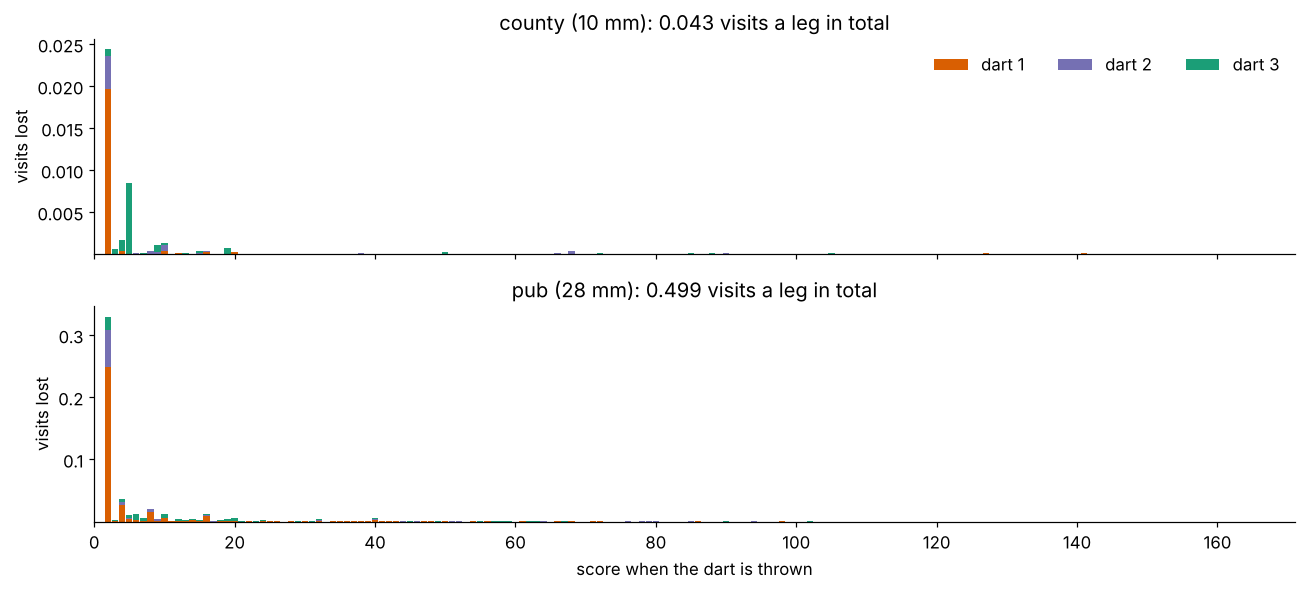

In [12]:
decs = {}
for band in ["county", "pub"]:
    k = kept[band]
    for name, pol in [("darts", as_policy(k["md"])), ("memoryless", as_policy(k["pmem"]))]:
        dec = decompose(k["tr"], pol, k["mv"])
        total = (dec.occupancy * dec.loss).sum()
        gap = k["res"][name]["visits"][START] - k["res"]["visits"]["visits"][START]
        assert abs(total - gap) < 1e-8, (total, gap)
        decs[band, name] = dec
        dec["contrib"] = dec.occupancy * dec.loss
        by_dart = dec.groupby("dart").contrib.sum()
        low = dec[dec.score <= 40].contrib.sum()
        on2 = dec[dec.score == 2].contrib.sum()
        print(f"{band:>7} {name:>10}: total {total:.4f} | by dart "
              f"{by_dart.round(4).to_dict()} | score<=40 {low / total:.0%} | on 2 {on2 / total:.0%}")

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
cols = {1: "#d95f02", 2: "#7570b3", 3: "#1b9e77"}
for ax, band in zip(axes, ["county", "pub"]):
    dec = decs[band, "darts"]
    g = dec.groupby(["score", "dart"]).contrib.sum().unstack(fill_value=0.0)
    g = g.reindex(range(2, 171), fill_value=0.0)
    bottom = np.zeros(len(g))
    for d in (1, 2, 3):
        vals = g.get(d, pd.Series(0.0, index=g.index)).values
        ax.bar(g.index, vals, bottom=bottom, width=0.9, color=cols[d], label=f"dart {d}")
        bottom += vals
    tot = dec.contrib.sum()
    ax.set(ylabel="visits lost", title=f"{band} ({BANDS[band]:g} mm): {tot:.3f} visits a leg in total")
axes[0].legend(frameon=False, ncol=3)
axes[1].set(xlabel="score when the dart is thrown", xlim=(0, 171))
fig.tight_layout()
fig.savefig(OUT / "where-the-visits-go.png", bbox_inches="tight")

## The cost of each wrong model, by ability

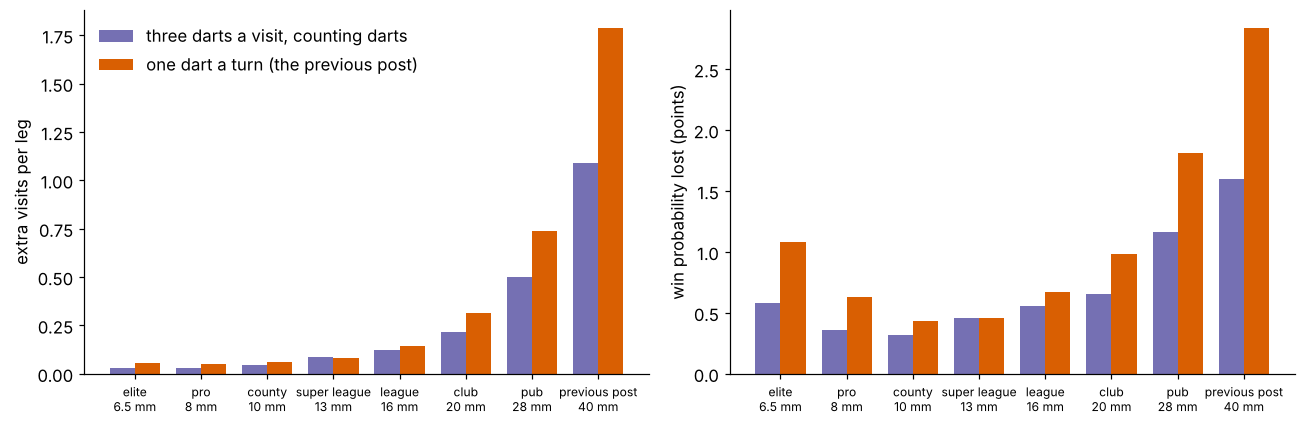

In [13]:
t = table
x = np.arange(len(t))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wd = 0.38
axes[0].bar(x - wd / 2, t.darts_visits - t.visits_visits, wd, color="#7570b3",
            label="three darts a visit, counting darts")
axes[0].bar(x + wd / 2, t.memoryless_visits - t.visits_visits, wd, color="#d95f02",
            label="one dart a turn (the previous post)")
axes[0].set(ylabel="extra visits per leg")
axes[1].bar(x - wd / 2, 100 * (0.5 - t.darts_win), wd, color="#7570b3")
axes[1].bar(x + wd / 2, 100 * (0.5 - t.memoryless_win), wd, color="#d95f02")
axes[1].set(ylabel="win probability lost (points)")
labels = [f"{b}\n{s:g} mm" for b, s in zip(t.index.str.replace("_", " "), t.sigma_mm)]
for ax in axes:
    ax.set_xticks(x, labels, fontsize=8)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "cost-by-ability.png", bbox_inches="tight")

## How big the state space is

In [14]:
m = kept["county"]["mv"]
naive = sum(1 + 2 * (s - 1) for s in range(2, START + 1))  # (u, dart, s): dart 1 has u = s
print("thresholds: dart 3 independent of the visit start from", m.u3_indep,
      "| dart 2 from", m.u2_indep, "| the whole visit from", m.s_indep)
print("visit-start-dependent states actually stored:",
      int(np.isfinite(m.V2low).sum() + np.isfinite(m.V3low).sum()))
print("aiming points:", m.n_points)

thresholds: dart 3 independent of the visit start from 62 | dart 2 from 122 | the whole visit from 182
visit-start-dependent states actually stored: 14580
aiming points: 29829
